<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/kinetic_theory/kintheory_ch2_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Kinetic Theory* — `kintheory_ch2_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Kinetic Theory Chapter 2 — Figures
**Kinetic Theory · Ch 2: Kinetic Theory**  
Tong lectures — SeoulTech PSE Lab

Figures produced:
- `kt_fig05_cross_section.png` — Differential cross section geometry (impact parameter, scattering angle)
- `kt_fig06_bbgky.png` — BBGKY hierarchy schematic
- `kt_fig07_htheorem.png` — H-function decreasing toward equilibrium
- `kt_fig08_sound_dispersion.png` — Ideal vs viscous fluid mode dispersion
- `kt_fig09_maxwell_boltzmann.png` — Maxwell-Boltzmann as unique Boltzmann equilibrium

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyBboxPatch, Ellipse
from matplotlib.patches import Rectangle, FancyArrow
import os

os.makedirs('figures', exist_ok=True)

BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
TEAL    = '#2dd4bf'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

def dark_fig(w=8, h=5):
    fig, ax = plt.subplots(figsize=(w, h))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_color(BORDER)
    ax.tick_params(colors=MUTED)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(TEAL)
    return fig, ax

SAVE_KW = dict(dpi=150, bbox_inches='tight', facecolor=BG)
print('Setup complete.')

Setup complete.


## Fig 5 — Differential Cross Section Geometry

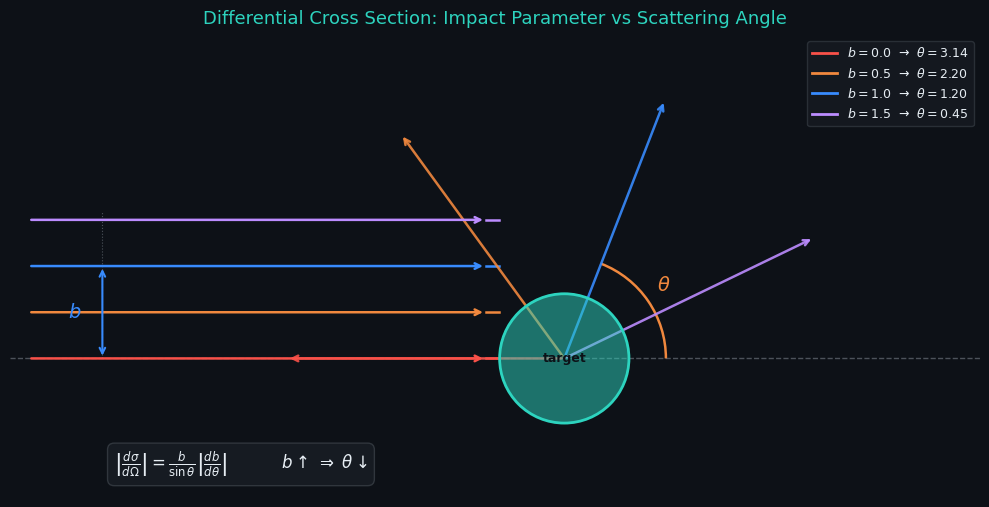

Saved kt_fig05_cross_section.png


In [2]:
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlim(-1.0, 9.5)
ax.set_ylim(-1.5, 3.5)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Scattering centre (sphere)
R = 0.7
cx, cy = 5.0, 0.0
sphere = Circle((cx, cy), R, color=TEAL, alpha=0.5, zorder=5)
ax.add_patch(sphere)
sphere_edge = Circle((cx, cy), R, color=TEAL, fill=False, lw=2.0, zorder=6)
ax.add_patch(sphere_edge)
ax.text(cx, cy, 'target', ha='center', va='center', fontsize=9,
        color=BG, fontweight='bold', zorder=7)

# Centre line (axis of symmetry)
ax.axhline(0, color=MUTED, lw=1.0, ls='--', alpha=0.5)

# Physically accurate b → θ relationship (central force scattering):
# b = (d/2) cos(θ/2)  →  θ = 2 arccos(2b/d) for hard spheres (b ≤ d/2)
# General rule: larger b → smaller θ (glancing incidence)
b_vals   = [0.0, 0.5, 1.0, 1.5]
colors_b = [RED, ORANGE, BLUE, PURPLE]
# b=0 → θ=π (head-on collision, 180° backscattering)
# b increases → θ decreases (grazing incidence, forward scattering)
theta_vals = [np.pi, 2.2, 1.2, 0.45]

for b, col, theta in zip(b_vals, colors_b, theta_vals):
    # Incoming ray (horizontal, from the left)
    x_stop = cx - R * np.cos(np.pi - theta/2) if b < R else cx - np.sqrt(R**2 - b**2) if b <= R else cx - 0.5
    ax.annotate('', xy=(cx - R - 0.15, b), xytext=(-0.8, b),
                arrowprops=dict(arrowstyle='->', color=col, lw=1.8))
    ax.plot([cx - R - 0.15, cx - R - 0.01], [b, b], color=col, lw=1.8)

    # Scattered ray (from sphere centre at angle θ)
    length = 3.0
    # Scattering angle θ measured from incident direction (x-axis)
    # b=0 gives θ=π (backscatter); increasing b gives smaller θ (forward scatter)
    dx = length * np.cos(theta)
    dy = length * np.sin(theta)
    ax.annotate('', xy=(cx + dx, dy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle='->', color=col, lw=1.8, alpha=0.9))

# Impact parameter label (shown for b=1.0)
b_show = 1.0
ax.annotate('', xy=(0.0, b_show), xytext=(0.0, 0.0),
            arrowprops=dict(arrowstyle='<->', color=BLUE, lw=1.5))
ax.text(-0.3, b_show/2, '$b$', ha='center', va='center', fontsize=14, color=BLUE)

# Scattering angle arc (shown for b=1.0, θ=1.2)
theta_show = 1.2
arc = Arc((cx, cy), 2.2, 2.2, angle=0,
          theta1=0, theta2=np.degrees(theta_show),
          color=ORANGE, lw=1.8)
ax.add_patch(arc)
ax.text(cx + 1.3*np.cos(theta_show/2), 1.3*np.sin(theta_show/2),
        r'$\theta$', ha='center', fontsize=14, color=ORANGE)

# Vertical dotted line (impact parameter reference)
ax.plot([0.0, 0.0], [0.0, 1.6], color=MUTED, lw=0.8, ls=':', alpha=0.5)

# Legend entries (b values)
for b, col, theta in zip(b_vals, colors_b, theta_vals):
    ax.plot([], [], color=col, lw=2.0,
            label=f'$b={b}$  →  $\\theta={theta:.2f}$')
ax.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER,
          labelcolor=TEXT, loc='upper right')

# Formula annotation box
ax.text(1.5, -1.2,
        r'$\left|\frac{d\sigma}{d\Omega}\right| = \frac{b}{\sin\theta}\left|\frac{db}{d\theta}\right|$'
        '          '
        r'$b \uparrow \;\Rightarrow\; \theta \downarrow$',
        ha='center', fontsize=12, color=TEXT,
        bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE, edgecolor=BORDER, lw=1))

ax.set_title('Differential Cross Section: Impact Parameter vs Scattering Angle',
             color=TEAL, fontsize=13, pad=8)
plt.tight_layout()
plt.savefig('figures/kt_fig05_cross_section.png', **SAVE_KW)
plt.show()
print('Saved kt_fig05_cross_section.png')

## Fig 6 — BBGKY Hierarchy Schematic

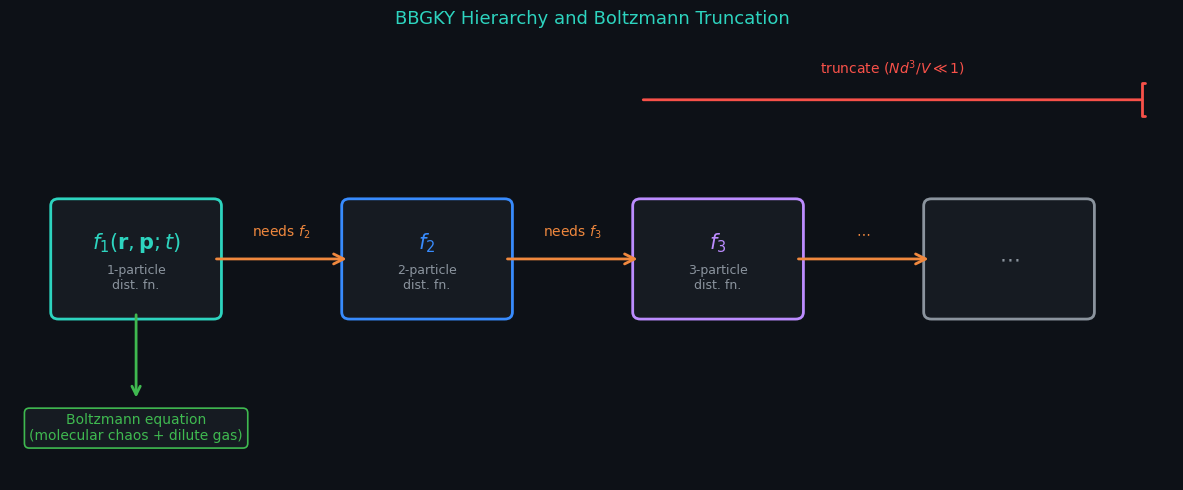

Saved kt_fig06_bbgky.png


In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.set_xticks([])
ax.set_yticks([])

# Box geometry: x, y (bottom-left corner), width, height — minimised box size
boxes = [
    (0.5,  1.9, 1.6, 1.2, r'$f_1(\mathbf{r},\mathbf{p};t)$', TEAL,   '1-particle\ndist. fn.'),
    (3.5,  1.9, 1.6, 1.2, r'$f_2$',                           BLUE,   '2-particle\ndist. fn.'),
    (6.5,  1.9, 1.6, 1.2, r'$f_3$',                           PURPLE, '3-particle\ndist. fn.'),
    (9.5,  1.9, 1.6, 1.2, r'$\cdots$',                        MUTED,  ''),
]

for x, y, w, h, label, col, sublabel in boxes:
    box = FancyBboxPatch((x, y), w, h,
                          boxstyle='round,pad=0.08',
                          facecolor=SURFACE, edgecolor=col, lw=2.0)
    ax.add_patch(box)
    cy = y + h/2
    if sublabel:
        ax.text(x + w/2, cy + 0.18, label,
                ha='center', va='center', fontsize=15, color=col, fontweight='bold')
        ax.text(x + w/2, cy - 0.22, sublabel,
                ha='center', va='center', fontsize=9, color=MUTED)
    else:
        ax.text(x + w/2, cy, label,
                ha='center', va='center', fontsize=15, color=col, fontweight='bold')

# Arrows: from right edge of left box to left edge of right box
arrow_pairs = [
    (boxes[0], boxes[1], 'needs $f_2$'),
    (boxes[1], boxes[2], 'needs $f_3$'),
    (boxes[2], boxes[3], r'$\cdots$'),
]
for (x1, y1, w1, h1, *_), (x2, y2, w2, h2, *_), label in arrow_pairs:
    x_start = x1 + w1
    x_end   = x2
    y_mid   = y1 + h1/2
    ax.annotate('', xy=(x_end, y_mid), xytext=(x_start, y_mid),
                arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.0,
                                mutation_scale=18))
    ax.text((x_start + x_end)/2, y_mid + 0.25, label,
            ha='center', fontsize=10, color=ORANGE)

# Downward arrow from f1 box to Boltzmann equation label
x_cx = boxes[0][0] + boxes[0][2]/2
y_bot = boxes[0][1]
ax.annotate('', xy=(x_cx, 0.9), xytext=(x_cx, y_bot),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.0, mutation_scale=15))
ax.text(x_cx, 0.45, 'Boltzmann equation\n(molecular chaos + dilute gas)',
        ha='center', fontsize=10, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.35', facecolor=SURFACE, edgecolor=GREEN, lw=1.2))

# Truncation marker (red bracket)
x_trunc = boxes[2][0]
ax.annotate('', xy=(11.7, 4.3), xytext=(x_trunc, 4.3),
            arrowprops=dict(arrowstyle='-[', color=RED, lw=2.0, mutation_scale=12))
ax.text((x_trunc + 11.7)/2, 4.6,
        r'truncate ($Nd^3/V \ll 1$)',
        ha='center', fontsize=10, color=RED)

ax.set_title('BBGKY Hierarchy and Boltzmann Truncation', color=TEAL, fontsize=13, pad=10)
plt.tight_layout()
plt.savefig('figures/kt_fig06_bbgky.png', **SAVE_KW)
plt.show()
print('Saved kt_fig06_bbgky.png')

## Fig 7 — H-Theorem: Entropy Increase

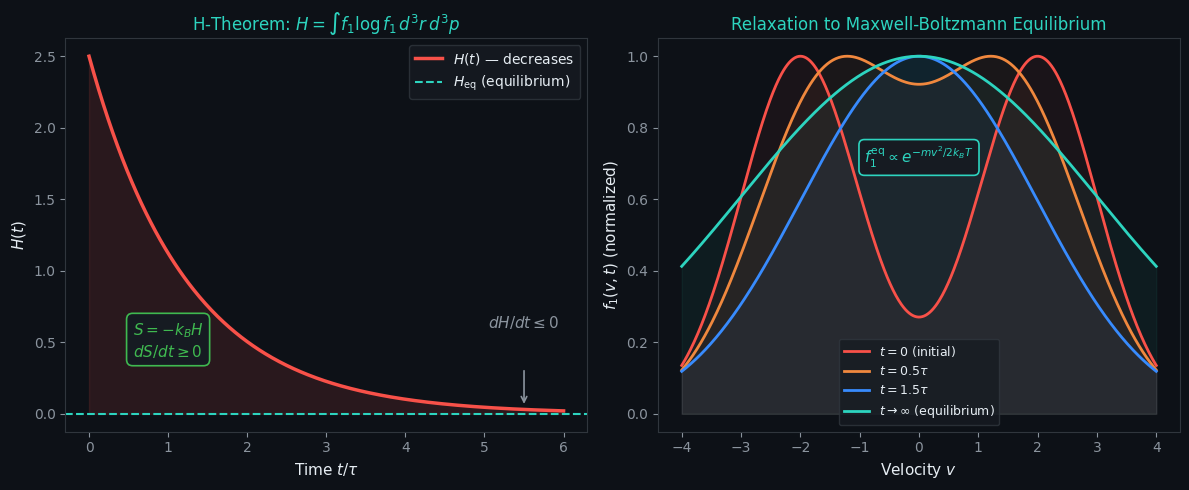

Saved kt_fig07_htheorem.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

# ── Left: H(t) decreasing ──
ax1 = axes[0]
ax1.set_facecolor(BG)
for sp in ax1.spines.values():
    sp.set_color(BORDER)
ax1.tick_params(colors=MUTED)

t = np.linspace(0, 6, 400)
H0, H_eq = 2.5, 0.0
H = H_eq + (H0 - H_eq) * np.exp(-t * 0.8)

ax1.plot(t, H, color=RED, lw=2.5, label=r'$H(t)$ — decreases')
ax1.axhline(H_eq, color=TEAL, lw=1.5, ls='--', label=r'$H_{\rm eq}$ (equilibrium)')
ax1.fill_between(t, H, H_eq, alpha=0.12, color=RED)

ax1.annotate('', xy=(5.5, H_eq + 0.05), xytext=(5.5, H[-1] + 0.3),
             arrowprops=dict(arrowstyle='->', color=MUTED, lw=1.2))
ax1.text(5.5, H_eq + 0.6, r'$dH/dt \leq 0$', ha='center', fontsize=11, color=MUTED)

ax1.set_xlabel('Time $t/\\tau$', color=TEXT, fontsize=11)
ax1.set_ylabel('$H(t)$', color=TEXT, fontsize=11)
ax1.set_title(r'H-Theorem: $H = \int f_1\log f_1\,d^3r\,d^3p$', color=TEAL, fontsize=12)
ax1.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax1.xaxis.label.set_color(TEXT)
ax1.yaxis.label.set_color(TEXT)

ax1.text(1.0, 0.4,
         r'$S = -k_B H$' '\n' r'$dS/dt \geq 0$',
         ha='center', fontsize=11, color=GREEN,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE, edgecolor=GREEN, lw=1.2))

# ── Right: time evolution of distribution function → relaxation to Maxwell-Boltzmann ──
ax2 = axes[1]
ax2.set_facecolor(BG)
for sp in ax2.spines.values():
    sp.set_color(BORDER)
ax2.tick_params(colors=MUTED)

v = np.linspace(-4, 4, 500)
T_eq = 1.0  # equilibrium temperature (normalised units)

# Initial distribution: non-equilibrium bimodal (two groups merging)
def bimodal(v, t):
    spread = 1.0 + t * 0.5
    peak_shift = 2.0 * np.exp(-t * 0.6)
    f = (np.exp(-(v - peak_shift)**2 / (2 * spread**2)) +
         np.exp(-(v + peak_shift)**2 / (2 * spread**2)))
    f /= f.max()
    return f

times_plot = [0.0, 0.5, 1.5, 4.0]
colors_t   = [RED, ORANGE, BLUE, TEAL]
labels_t   = ['$t=0$ (initial)', '$t=0.5\\tau$', '$t=1.5\\tau$', '$t\\to\\infty$ (equilibrium)']

for t_val, col, lbl in zip(times_plot, colors_t, labels_t):
    fv = bimodal(v, t_val)
    ax2.plot(v, fv, color=col, lw=2.0, label=lbl)
    ax2.fill_between(v, fv, alpha=0.06, color=col)

ax2.set_xlabel('Velocity $v$', color=TEXT, fontsize=11)
ax2.set_ylabel('$f_1(v,t)$ (normalized)', color=TEXT, fontsize=11)
ax2.set_title('Relaxation to Maxwell-Boltzmann Equilibrium', color=TEAL, fontsize=12)
ax2.legend(loc="lower center", fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax2.xaxis.label.set_color(TEXT)
ax2.yaxis.label.set_color(TEXT)

ax2.text(0, 0.7,
         r'$f_1^{\rm eq} \propto e^{-mv^2/2k_BT}$',
         ha='center', fontsize=11, color=TEAL,
         bbox=dict(boxstyle='round,pad=0.35', facecolor=SURFACE, edgecolor=TEAL, lw=1.2))

plt.tight_layout()
plt.savefig('figures/kt_fig07_htheorem.png', **SAVE_KW)
plt.show()
print('Saved kt_fig07_htheorem.png')

## Fig 8 — Fluid Mode Dispersion: Ideal vs Navier-Stokes

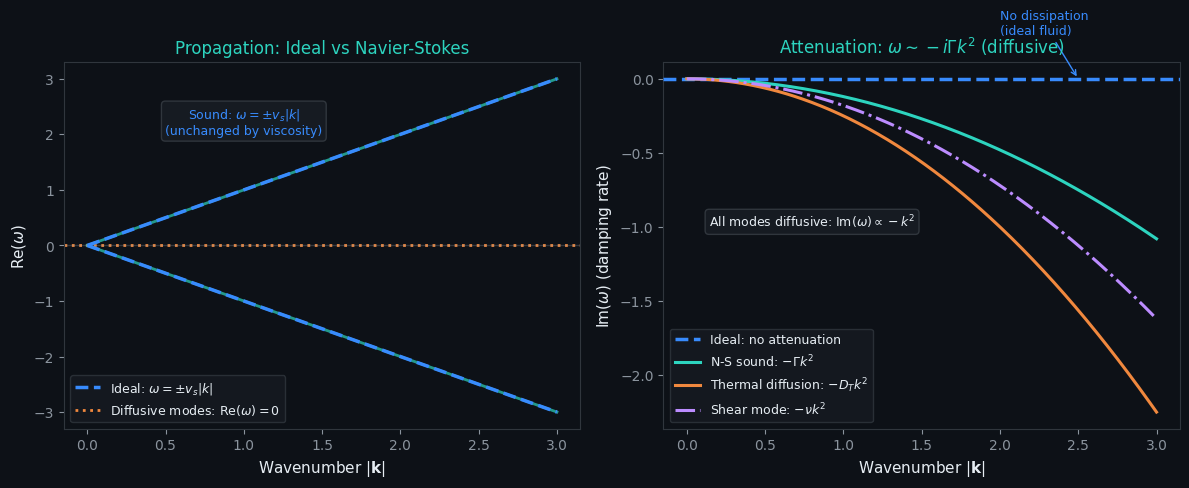

Saved kt_fig08_sound_dispersion.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

k = np.linspace(0, 3, 400)
vs = 1.0   # sound speed (normalised)
Gam = 0.12  # acoustic attenuation coefficient
D_th = 0.25  # thermal diffusion coefficient
D_sh = 0.18  # shear (viscous) diffusion coefficient

# ── Left: Re(ω) — propagation ──
ax1 = axes[0]
ax1.set_facecolor(BG)
for sp in ax1.spines.values():
    sp.set_color(BORDER)
ax1.tick_params(colors=MUTED)

# Ideal fluid: linear dispersion ω = ±vs|k|
ax1.plot(k,  vs*k, color=BLUE, lw=2.5, ls='--', label=r'Ideal: $\omega=\pm v_s|k|$', zorder=3)
ax1.plot(k, -vs*k, color=BLUE, lw=2.5, ls='--', zorder=3)

# Navier-Stokes: acoustic modes have identical Re(ω) — correction enters only Im(ω)
ax1.plot(k,  vs*k, color=TEAL, lw=2.0, alpha=0.7, zorder=2)
ax1.plot(k, -vs*k, color=TEAL, lw=2.0, alpha=0.7, zorder=2)

# Diffusive modes: Re(ω)=0 (purely imaginary frequency)
ax1.axhline(0, color=ORANGE, lw=2.0, ls=':', label=r'Diffusive modes: $\mathrm{Re}(\omega)=0$')
ax1.axhline(0, color=MUTED,  lw=1.0, ls='-', alpha=0.3)

ax1.set_xlabel('Wavenumber $|\\mathbf{k}|$', color=TEXT, fontsize=11)
ax1.set_ylabel(r'$\mathrm{Re}(\omega)$', color=TEXT, fontsize=11)
ax1.set_title('Propagation: Ideal vs Navier-Stokes', color=TEAL, fontsize=12)
ax1.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax1.xaxis.label.set_color(TEXT)
ax1.yaxis.label.set_color(TEXT)

ax1.text(1.0, 2.0,
         'Sound: $\\omega = \\pm v_s|k|$\n(unchanged by viscosity)',
         ha='center', fontsize=9, color=BLUE,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=SURFACE, edgecolor=BORDER, lw=1))

# ── Right: Im(ω) — attenuation (physically accurate coefficients) ──
ax2 = axes[1]
ax2.set_facecolor(BG)
for sp in ax2.spines.values():
    sp.set_color(BORDER)
ax2.tick_params(colors=MUTED)

# Ideal fluid: Im(ω)=0, no dissipation
ax2.axhline(0, color=BLUE, lw=2.5, ls='--', label='Ideal: no attenuation', zorder=3)

# Navier-Stokes acoustic mode: Im(ω) = -Γ k² (acoustic attenuation)
ax2.plot(k, -Gam * k**2, color=TEAL, lw=2.2,
         label=r'N-S sound: $-\Gamma k^2$', zorder=4)

# Thermal diffusion mode: Im(ω) = -D_T k²
ax2.plot(k, -D_th * k**2, color=ORANGE, lw=2.2,
         label=r'Thermal diffusion: $-D_T k^2$', zorder=4)

# Shear (viscous) mode: Im(ω) = -ν k²
ax2.plot(k, -D_sh * k**2, color=PURPLE, lw=2.2, ls='-.',
         label=r'Shear mode: $-\nu k^2$', zorder=4)

ax2.set_xlabel('Wavenumber $|\\mathbf{k}|$', color=TEXT, fontsize=11)
ax2.set_ylabel(r'$\mathrm{Im}(\omega)$ (damping rate)', color=TEXT, fontsize=11)
ax2.set_title('Attenuation: $\\omega \\sim -i\\Gamma k^2$ (diffusive)', color=TEAL, fontsize=12)
ax2.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax2.xaxis.label.set_color(TEXT)
ax2.yaxis.label.set_color(TEXT)

# Annotation: ideal fluid has no dissipation
ax2.annotate('No dissipation\n(ideal fluid)',
             xy=(2.5, 0), xytext=(2.0, 0.3),
             fontsize=9, color=BLUE,
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.0))

ax2.text(0.8, -1.0,
         r'All modes diffusive: $\mathrm{Im}(\omega) \propto -k^2$',
         ha='center', fontsize=9, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=SURFACE, edgecolor=BORDER, lw=1))

plt.tight_layout()
plt.savefig('figures/kt_fig08_sound_dispersion.png', **SAVE_KW)
plt.show()
print('Saved kt_fig08_sound_dispersion.png')

## Fig 9 — Maxwell-Boltzmann as Unique Boltzmann Equilibrium

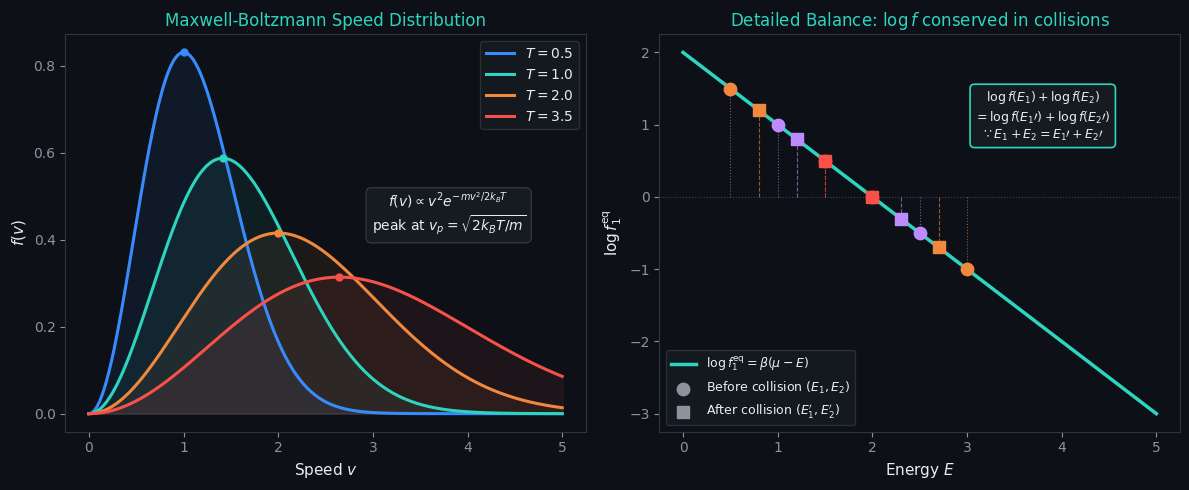

Saved kt_fig09_maxwell_boltzmann.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

# ── Left: Maxwell-Boltzmann speed distribution (3D) ──
ax1 = axes[0]
ax1.set_facecolor(BG)
for sp in ax1.spines.values():
    sp.set_color(BORDER)
ax1.tick_params(colors=MUTED)

v = np.linspace(0, 5, 400)
temps   = [0.5, 1.0, 2.0, 3.5]
colors_T = [BLUE, TEAL, ORANGE, RED]

for T, col in zip(temps, colors_T):
    # 3D Maxwell-Boltzmann speed distribution: f(v) = 4π (m/2πkT)^{3/2} v² exp(-mv²/2kT)
    # units: m=1, kB=1
    fv = 4*np.pi * (1/(2*np.pi*T))**1.5 * v**2 * np.exp(-v**2/(2*T))
    ax1.plot(v, fv, color=col, lw=2.2, label=f'$T = {T}$')
    ax1.fill_between(v, fv, alpha=0.07, color=col)
    # Mark the most probable speed: v_peak = sqrt(2kT/m)
    v_peak = np.sqrt(2*T)
    f_peak = 4*np.pi * (1/(2*np.pi*T))**1.5 * v_peak**2 * np.exp(-1)
    ax1.plot(v_peak, f_peak, 'o', color=col, ms=5, zorder=5)

ax1.set_xlabel('Speed $v$', color=TEXT, fontsize=11)
ax1.set_ylabel('$f(v)$', color=TEXT, fontsize=11)
ax1.set_title('Maxwell-Boltzmann Speed Distribution', color=TEAL, fontsize=12)
ax1.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax1.xaxis.label.set_color(TEXT)
ax1.yaxis.label.set_color(TEXT)

ax1.text(3.8, 0.42,
         r'$f(v) \propto v^2 e^{-mv^2/2k_BT}$' '\n' r'peak at $v_p = \sqrt{2k_BT/m}$',
         ha='center', fontsize=10, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE, edgecolor=BORDER, lw=1))

# ── Right: verification of detailed balance ──
# log f1(p1') + log f1(p2') = log f1(p1) + log f1(p2)
# For MB: log f = β(μ - E), and energy conservation E1+E2 = E1'+E2' ensures equality
ax2 = axes[1]
ax2.set_facecolor(BG)
for sp in ax2.spines.values():
    sp.set_color(BORDER)
ax2.tick_params(colors=MUTED)

E = np.linspace(0, 5, 300)
T_ref = 1.0
beta  = 1.0 / T_ref
mu    = 2.0  # chemical potential (arbitrary, sets normalisation)

log_f_MB = beta * (mu - E)

# Example energy pairs before and after collision
pairs_in  = [(0.5, 3.0), (1.0, 2.5), (1.5, 2.0)]  # E1 + E2 = 3.5 (conserved)
pairs_out = [(0.8, 2.7), (1.2, 2.3), (2.0, 1.5)]   # E1'+ E2'= 3.5 (same total)

ax2.plot(E, log_f_MB, color=TEAL, lw=2.5, label=r'$\log f_1^{\rm eq} = \beta(\mu - E)$', zorder=5)

colors_pairs = [ORANGE, PURPLE, RED]
for (e1, e2), (e1p, e2p), col in zip(pairs_in, pairs_out, colors_pairs):
    lf1  = beta*(mu - e1);  lf2  = beta*(mu - e2)
    lf1p = beta*(mu - e1p); lf2p = beta*(mu - e2p)
        # Two points before collision
    ax2.scatter([e1, e2], [lf1, lf2], color=col, s=80, zorder=6, marker='o')
        # Two points after collision
    ax2.scatter([e1p, e2p], [lf1p, lf2p], color=col, s=80, zorder=6, marker='s')
        # Vertical dotted lines showing conserved sum for each pair
    ax2.plot([e1, e1], [0, lf1],   color=col, lw=0.8, ls=':', alpha=0.6)
    ax2.plot([e2, e2], [0, lf2],   color=col, lw=0.8, ls=':', alpha=0.6)
    ax2.plot([e1p, e1p], [0, lf1p], color=col, lw=0.8, ls='--', alpha=0.6)
    ax2.plot([e2p, e2p], [0, lf2p], color=col, lw=0.8, ls='--', alpha=0.6)

# Legend proxy items
ax2.scatter([], [], color=MUTED, s=80, marker='o', label='Before collision ($E_1, E_2$)')
ax2.scatter([], [], color=MUTED, s=80, marker='s', label="After collision ($E_1', E_2'$)")
ax2.axhline(0, color=MUTED, lw=0.8, ls=':', alpha=0.4)

ax2.set_xlabel('Energy $E$', color=TEXT, fontsize=11)
ax2.set_ylabel(r'$\log f_1^{\rm eq}$', color=TEXT, fontsize=11)
ax2.set_title('Detailed Balance: $\\log f$ conserved in collisions', color=TEAL, fontsize=12)
ax2.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax2.xaxis.label.set_color(TEXT)
ax2.yaxis.label.set_color(TEXT)

ax2.text(3.8, 0.8,
         r'$\log f(E_1) + \log f(E_2)$' '\n'
         r'$= \log f(E_1\prime) + \log f(E_2\prime)$' '\n'
         r'$\because E_1+E_2 = E_1\prime+E_2\prime$',
         ha='center', fontsize=9, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.35', facecolor=SURFACE, edgecolor=TEAL, lw=1.2))

plt.tight_layout()
plt.savefig('figures/kt_fig09_maxwell_boltzmann.png', **SAVE_KW)
plt.show()
print('Saved kt_fig09_maxwell_boltzmann.png')

## Download all figures as zip

In [7]:
import zipfile, os
zip_path = 'kt_ch2_figures.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.startswith('kt_fig0') and fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)
            print(f'  Added: {fname}')
print(f'\nZip: {zip_path}  ({os.path.getsize(zip_path)/1024:.1f} KB)')
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Not in Colab — file saved locally.')

  Added: kt_fig05_cross_section.png
  Added: kt_fig06_bbgky.png
  Added: kt_fig07_htheorem.png
  Added: kt_fig08_sound_dispersion.png
  Added: kt_fig09_maxwell_boltzmann.png

Zip: kt_ch2_figures.zip  (541.6 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>